In [1]:
import sys
print(sys.executable)

c:\Users\ASUS TUF GAMING\Projects\Laptop_price_prediction_recommendation\venv\Scripts\python.exe


In [2]:
import pandas as pd
import numpy as np

df = pd.read_csv("../data/laptop_data.csv")

df.head()

,Unnamed: 0,Company,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price
0,0,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8GB,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37kg,71378.6832
1,1,Apple,Ultrabook,13.3,1440x900,Intel Core i5 1.8GHz,8GB,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34kg,47895.5232
2,2,HP,Notebook,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8GB,256GB SSD,Intel HD Graphics 620,No OS,1.86kg,30636.0000
3,3,Apple,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,16GB,512GB SSD,AMD Radeon Pro 455,macOS,1.83kg,135195.3360
4,4,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,8GB,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37kg,96095.8080


In [3]:
df.shape

(1303, 12)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1303 entries, 0 to 1302
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Unnamed: 0        1303 non-null   int64  
 1   Company           1303 non-null   str    
 2   TypeName          1303 non-null   str    
 3   Inches            1303 non-null   float64
 4   ScreenResolution  1303 non-null   str    
 5   Cpu               1303 non-null   str    
 6   Ram               1303 non-null   str    
 7   Memory            1303 non-null   str    
 8   Gpu               1303 non-null   str    
 9   OpSys             1303 non-null   str    
 10  Weight            1303 non-null   str    
 11  Price             1303 non-null   float64
dtypes: float64(2), int64(1), str(9)
memory usage: 122.3 KB


In [5]:
df.isnull().sum()

Unnamed: 0          0
Company             0
TypeName            0
Inches              0
ScreenResolution    0
Cpu                 0
Ram                 0
Memory              0
Gpu                 0
OpSys               0
Weight              0
Price               0
dtype: int64

In [6]:
df.duplicated().sum()

np.int64(0)

In [7]:
df.drop(columns=['Unnamed: 0'], inplace=True)

In [8]:
df['Ram'] = df['Ram'].str.replace('GB','').astype(int)

In [9]:
df['Weight'] = df['Weight'].str.replace('kg','').astype(float)

In [10]:
df['Inches'] = df['Inches'].astype(float)

In [11]:
df['Touchscreen'] = df['ScreenResolution'].apply(lambda x:1 if 'Touchscreen' in x else 0)

In [12]:
df['Ips'] = df['ScreenResolution'].apply(lambda x:1 if 'IPS' in x else 0)

## Feature Engineering

### CPU

In [13]:
df['Cpu'].unique()

<StringArray>
[                'Intel Core i5 2.3GHz',
                 'Intel Core i5 1.8GHz',
           'Intel Core i5 7200U 2.5GHz',
                 'Intel Core i7 2.7GHz',
                 'Intel Core i5 3.1GHz',
              'AMD A9-Series 9420 3GHz',
                 'Intel Core i7 2.2GHz',
           'Intel Core i7 8550U 1.8GHz',
           'Intel Core i5 8250U 1.6GHz',
             'Intel Core i3 6006U 2GHz',
 ...
                  'Intel Core M 1.1GHz',
 'Intel Pentium Dual Core 4405Y 1.5GHz',
 'Intel Pentium Quad Core N3700 1.6GHz',
             'Intel Core M 6Y54 1.1GHz',
          'Intel Core i7 6500U 2.50GHz',
   'Intel Celeron Dual Core N3350 2GHz',
        'Samsung Cortex A72&A53 2.0GHz',
             'AMD E-Series 9000 2.2GHz',
             'Intel Core M 6Y30 0.9GHz',
            'AMD A9-Series 9410 2.9GHz']
Length: 118, dtype: str

In [14]:
df['Cpu Name'] = df['Cpu'].apply(lambda x: " ".join(x.split()[:3]))

In [15]:
df[['Cpu','Cpu Name']].head(15)

,Cpu,Cpu Name
0,Intel Core i5 2.3GHz,Intel Core i5
1,Intel Core i5 1.8GHz,Intel Core i5
2,Intel Core i5 7200U 2.5GHz,Intel Core i5
3,Intel Core i7 2.7GHz,Intel Core i7
4,Intel Core i5 3.1GHz,Intel Core i5
5,AMD A9-Series 9420 3GHz,AMD A9-Series 9420
6,Intel Core i7 2.2GHz,Intel Core i7
7,Intel Core i5 1.8GHz,Intel Core i5
8,Intel Core i7 8550U 1.8GHz,Intel Core i7
9,Intel Core i5 8250U 1.6GHz,Intel Core i5


In [16]:
def fetch_processor(cpu):
    if cpu in ['Intel Core i3', 'Intel Core i5', 'Intel Core i7']:
        return cpu

    elif cpu.startswith('AMD'):
        return 'AMD'

    elif cpu.startswith('Intel Celeron'):
        return 'Intel Celeron'

    elif cpu.startswith('Intel Pentium'):
        return 'Intel Pentium'

    else:
        return 'Other Intel'

In [17]:
df['Cpu Brand'] = df['Cpu Name'].apply(fetch_processor)

In [18]:
df['Cpu Brand'].value_counts()

Cpu Brand
Intel Core i7    527
Intel Core i5    423
Intel Core i3    136
Intel Celeron     88
AMD               62
Other Intel       37
Intel Pentium     30
Name: count, dtype: int64

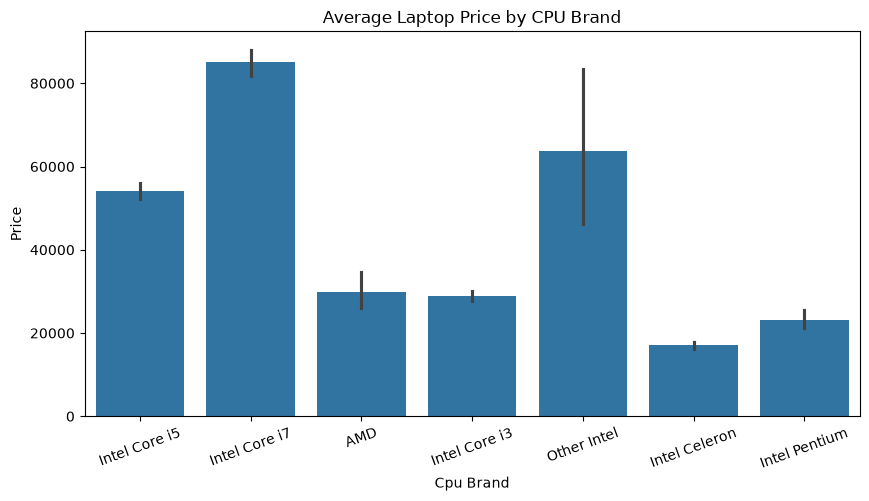

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10,5))

sns.barplot(
    data=df,
    x='Cpu Brand',
    y='Price',
    estimator='mean'
)

plt.xticks(rotation=20)
plt.title('Average Laptop Price by CPU Brand')
plt.show()

In [20]:
df.drop(columns=['Cpu', 'Cpu Name'], inplace=True)

### Screen Resolution

In [21]:
df['Resolution'] = df['ScreenResolution'].str.extract(r'(\d+x\d+)')

In [22]:
df[['ScreenResolution','Resolution']].head(10)

,ScreenResolution,Resolution
0,IPS Panel Retina Display 2560x1600,2560x1600
1,1440x900,1440x900
2,Full HD 1920x1080,1920x1080
3,IPS Panel Retina Display 2880x1800,2880x1800
4,IPS Panel Retina Display 2560x1600,2560x1600
5,1366x768,1366x768
6,IPS Panel Retina Display 2880x1800,2880x1800
7,1440x900,1440x900
8,Full HD 1920x1080,1920x1080
9,IPS Panel Full HD 1920x1080,1920x1080


In [23]:
df['X_res'] = df['Resolution'].str.split('x').str[0].astype(int)

df['Y_res'] = df['Resolution'].str.split('x').str[1].astype(int)

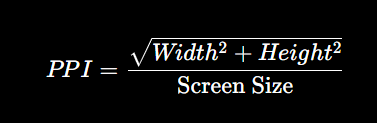

In [24]:
import numpy as np

df['PPI'] = (
    np.sqrt(df['X_res']**2 + df['Y_res']**2)
) / df['Inches']

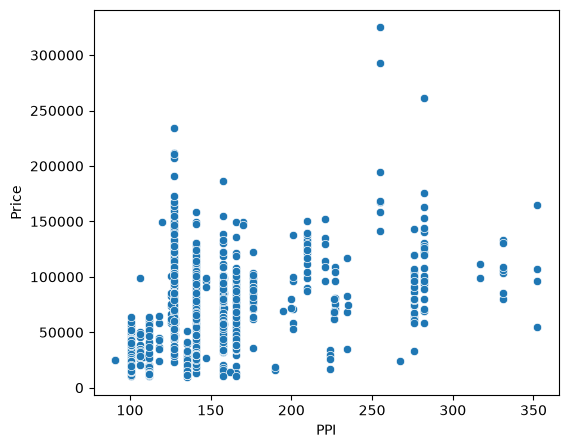

In [25]:
plt.figure(figsize=(6,5))
sns.scatterplot(data=df, x='PPI', y='Price')
plt.show()

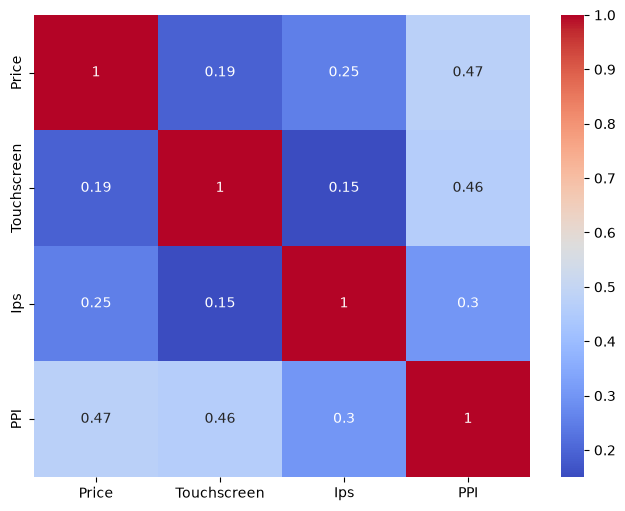

In [26]:
plt.figure(figsize=(8,6))

sns.heatmap(
    df[['Price','Touchscreen','Ips','PPI']].corr(),
    annot=True,
    cmap='coolwarm'
)

plt.show()

In [27]:
df.drop(columns=['ScreenResolution', 'Resolution'], inplace=True)

## Memory

In [28]:
memory = df['Memory'].str.replace('TB', '000GB', regex=False)
memory = memory.str.replace('.0', '', regex=False)

In [29]:
df['SSD'] = 0
df['HDD'] = 0
df['Flash'] = 0
df['Hybrid'] = 0

In [ ]:
import re

for i in range(len(df)):

    items = memory.iloc[i].split('+')

    for item in items:

        item = item.strip()

        size = int(re.search(r'(\d+)', item).group())

        if 'SSD' in item:
            df.at[i, 'SSD'] += size

        elif 'HDD' in item:
            df.at[i, 'HDD'] += size

        elif 'Flash Storage' in item:
            df.at[i, 'Flash'] += size

        elif 'Hybrid' in item:
            df.at[i, 'Hybrid'] += size

In [31]:
df[['Memory','SSD','HDD','Flash','Hybrid']].head(15)

,Memory,SSD,HDD,Flash,Hybrid
0,128GB SSD,128,0,0,0
1,128GB Flash Storage,0,0,128,0
2,256GB SSD,256,0,0,0
3,512GB SSD,512,0,0,0
4,256GB SSD,256,0,0,0
5,500GB HDD,0,500,0,0
6,256GB Flash Storage,0,0,256,0
7,256GB Flash Storage,0,0,256,0
8,512GB SSD,512,0,0,0
9,256GB SSD,256,0,0,0


## GPU

In [32]:
df['Gpu Brand'] = df['Gpu'].apply(lambda x: x.split()[0])

In [33]:
df[['Gpu','Gpu Brand']].head(10)

,Gpu,Gpu Brand
0,Intel Iris Plus Graphics 640,Intel
1,Intel HD Graphics 6000,Intel
2,Intel HD Graphics 620,Intel
3,AMD Radeon Pro 455,AMD
4,Intel Iris Plus Graphics 650,Intel
5,AMD Radeon R5,AMD
6,Intel Iris Pro Graphics,Intel
7,Intel HD Graphics 6000,Intel
8,Nvidia GeForce MX150,Nvidia
9,Intel UHD Graphics 620,Intel


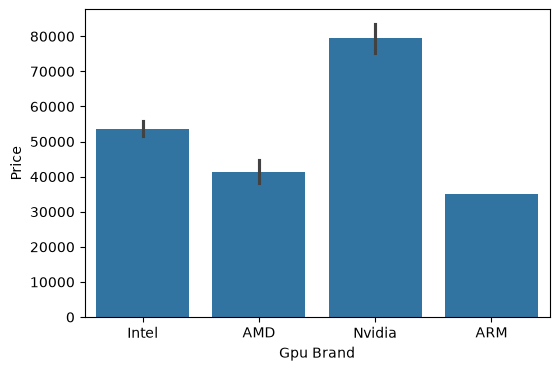

In [34]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6,4))

sns.barplot(
    data=df,
    x='Gpu Brand',
    y='Price',
    estimator='mean'
)

plt.show()

In [35]:
df.drop(columns=['Gpu'], inplace=True)

## Operating System

In [36]:
df['OpSys'].value_counts()

OpSys
Windows 10      1072
No OS             66
Linux             62
Windows 7         45
Chrome OS         27
macOS             13
Mac OS X           8
Windows 10 S       8
Android            2
Name: count, dtype: int64

In [37]:
def categorize_os(os):

    if 'Windows' in os:
        return 'Windows'

    elif 'Mac' in os or 'macOS' in os:
        return 'Mac'

    elif 'Linux' in os:
        return 'Linux'

    elif 'Chrome' in os:
        return 'Chrome OS'

    elif 'Android' in os:
        return 'Android'

    else:
        return 'Other'

In [38]:
df['OS'] = df['OpSys'].apply(categorize_os)

In [39]:
df['OS'].value_counts()

OS
Windows      1125
Other          66
Linux          62
Chrome OS      27
Mac            21
Android         2
Name: count, dtype: int64

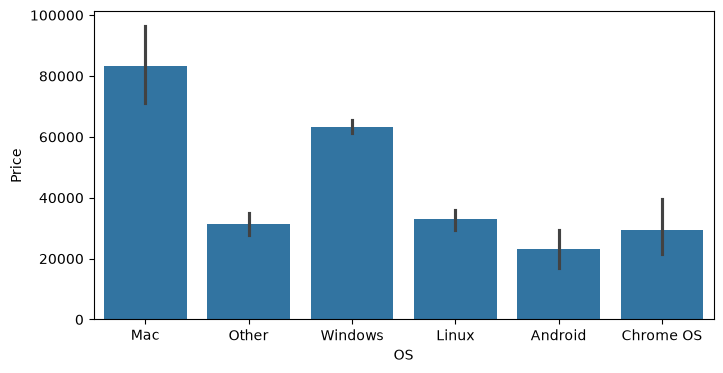

In [40]:
plt.figure(figsize=(8,4))

sns.barplot(
    data=df,
    x='OS',
    y='Price',
    estimator='mean'
)

plt.show()

In [41]:
df.drop(columns=['OpSys'], inplace=True)

In [42]:
df.drop(columns=['X_res', 'Y_res'], inplace=True)

In [43]:
df.drop(columns=['Inches', 'Memory'], inplace=True)

In [44]:
df.head()

,Company,TypeName,Ram,Weight,Price,Touchscreen,Ips,Cpu Brand,PPI,SSD,HDD,Flash,Hybrid,Gpu Brand,OS
0,Apple,Ultrabook,8,1.37,71378.6832,0,1,Intel Core i5,226.983005,128,0,0,0,Intel,Mac
1,Apple,Ultrabook,8,1.34,47895.5232,0,0,Intel Core i5,127.677940,0,0,128,0,Intel,Mac
2,HP,Notebook,8,1.86,30636.0000,0,0,Intel Core i5,141.211998,256,0,0,0,Intel,Other
3,Apple,Ultrabook,16,1.83,135195.3360,0,1,Intel Core i7,220.534624,512,0,0,0,AMD,Mac
4,Apple,Ultrabook,8,1.37,96095.8080,0,1,Intel Core i5,226.983005,256,0,0,0,Intel,Mac


In [45]:
df.columns

Index(['Company', 'TypeName', 'Ram', 'Weight', 'Price', 'Touchscreen', 'Ips',
       'Cpu Brand', 'PPI', 'SSD', 'HDD', 'Flash', 'Hybrid', 'Gpu Brand', 'OS'],
      dtype='str')

In [46]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1303 entries, 0 to 1302
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Company      1303 non-null   str    
 1   TypeName     1303 non-null   str    
 2   Ram          1303 non-null   int64  
 3   Weight       1303 non-null   float64
 4   Price        1303 non-null   float64
 5   Touchscreen  1303 non-null   int64  
 6   Ips          1303 non-null   int64  
 7   Cpu Brand    1303 non-null   str    
 8   PPI          1303 non-null   float64
 9   SSD          1303 non-null   int64  
 10  HDD          1303 non-null   int64  
 11  Flash        1303 non-null   int64  
 12  Hybrid       1303 non-null   int64  
 13  Gpu Brand    1303 non-null   str    
 14  OS           1303 non-null   str    
dtypes: float64(3), int64(7), str(5)
memory usage: 152.8 KB


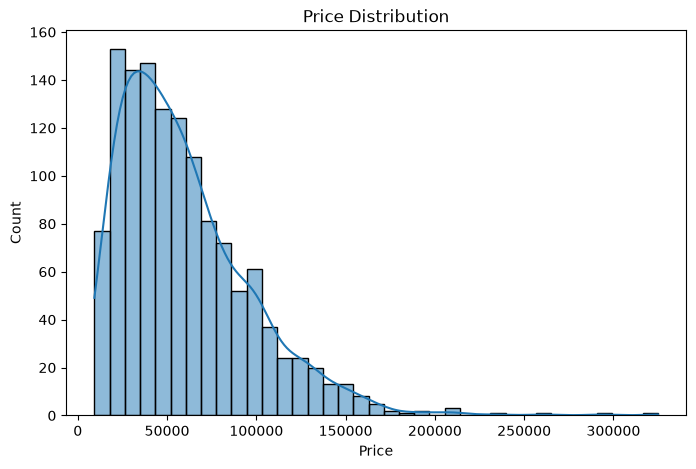

In [47]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8,5))
sns.histplot(df['Price'], kde=True)
plt.title("Price Distribution")
plt.show()

In [48]:
import numpy as np

df['Price'] = np.log(df['Price'])

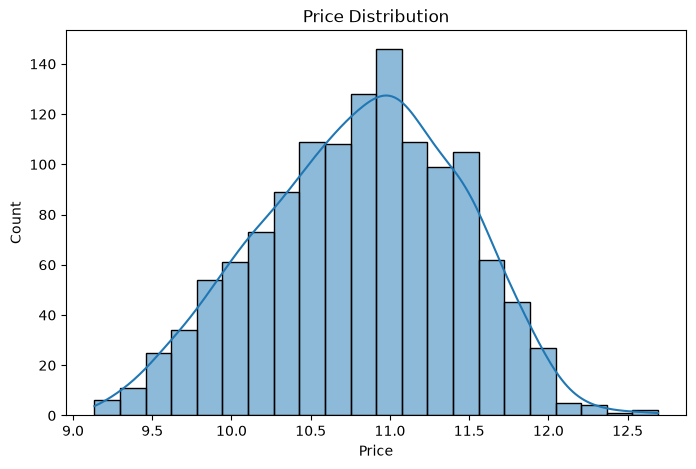

In [49]:
plt.figure(figsize=(8,5))
sns.histplot(df['Price'], kde=True)
plt.title("Price Distribution")
plt.show()

## Training part

In [50]:
X = df.drop(columns=['Price'])
y = df['Price']

In [51]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [52]:
categorical_features = [
    'Company',
    'TypeName',
    'Cpu Brand',
    'Gpu Brand',
    'OS'
]

numerical_features = [
    'Ram',
    'Weight',
    'Touchscreen',
    'Ips',
    'PPI',
    'SSD',
    'HDD',
    'Flash',
    'Hybrid'
]

In [53]:
print("Categorical:", categorical_features)
print("Numerical:", numerical_features)

Categorical: ['Company', 'TypeName', 'Cpu Brand', 'Gpu Brand', 'OS']
Numerical: ['Ram', 'Weight', 'Touchscreen', 'Ips', 'PPI', 'SSD', 'HDD', 'Flash', 'Hybrid']


In [54]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

preprocessor_lr = ColumnTransformer(
    transformers=[
        (
            'cat',
            OneHotEncoder(handle_unknown='ignore'),
            categorical_features
        ),
        (
            'num',
            StandardScaler(),
            numerical_features
        )
    ]
)

In [55]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

lr_pipeline = Pipeline([
    ('preprocessor', preprocessor_lr),
    ('model', LinearRegression())
])

lr_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](14,)","['Company','TypeName','Ram',...,'Hybrid','Gpu Brand','OS']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,14
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenat

In [56]:
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)
import numpy as np

y_pred_lr = lr_pipeline.predict(X_test)

print("Linear Regression")
print("R² Score :", r2_score(y_test, y_pred_lr))
print("MAE      :", mean_absolute_error(y_test, y_pred_lr))
print("RMSE     :", np.sqrt(mean_squared_error(y_test, y_pred_lr)))

Linear Regression
R² Score : 0.8406020636636528
MAE      : 0.18771939764925843
RMSE     : 0.2376854365777386


In [57]:
preprocessor_tree = ColumnTransformer(
    transformers=[
        (
            'cat',
            OneHotEncoder(handle_unknown='ignore'),
            categorical_features
        )
    ],
    remainder='passthrough'
)

In [58]:
df[categorical_features]

,Company,TypeName,Cpu Brand,Gpu Brand,OS
0,Apple,Ultrabook,Intel Core i5,Intel,Mac
1,Apple,Ultrabook,Intel Core i5,Intel,Mac
2,HP,Notebook,Intel Core i5,Intel,Other
3,Apple,Ultrabook,Intel Core i7,AMD,Mac
4,Apple,Ultrabook,Intel Core i5,Intel,Mac
...,...,...,...,...,...
1298,Lenovo,2 in 1 Convertible,Intel Core i7,Intel,Windows
1299,Lenovo,2 in 1 Convertible,Intel Core i7,Intel,Windows
1300,Lenovo,Notebook,Intel Celeron,Intel,Windows
1301,HP,Notebook,Intel Core i7,AMD,Windows


In [59]:
df[numerical_features]

,Ram,Weight,Touchscreen,Ips,PPI,SSD,HDD,Flash,Hybrid
0,8,1.37,0,1,226.983005,128,0,0,0
1,8,1.34,0,0,127.677940,0,0,128,0
2,8,1.86,0,0,141.211998,256,0,0,0
3,16,1.83,0,1,220.534624,512,0,0,0
4,8,1.37,0,1,226.983005,256,0,0,0
...,...,...,...,...,...,...,...,...,...
1298,4,1.80,1,1,157.350512,128,0,0,0
1299,16,1.30,1,1,276.053530,512,0,0,0
1300,2,1.50,0,0,111.935204,0,0,64,0
1301,6,2.19,0,0,100.454670,0,1000,0,0


In [60]:
preprocessor_tree = ColumnTransformer(
    transformers=[
        (
            'cat',
            OneHotEncoder(handle_unknown='ignore'),
            categorical_features
        )
    ],
    remainder='passthrough'
)

In [61]:
from sklearn.pipeline import Pipeline

def evaluate_tree_model(model):

    pipeline = Pipeline([
        ('preprocessor', preprocessor_tree),
        ('model', model)
    ])

    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_test)

    r2 = r2_score(y_test, predictions)
    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))

    return pipeline, r2, mae, rmse

## Decision Treee

In [62]:
from sklearn.tree import DecisionTreeRegressor

dt_model, dt_r2, dt_mae, dt_rmse = evaluate_tree_model(
    DecisionTreeRegressor(random_state=42)
)

print("Decision Tree")
print("R² :", dt_r2)
print("MAE:", dt_mae)
print("RMSE:", dt_rmse)

Decision Tree
R² : 0.7917841513478403
MAE: 0.19889683455163462
RMSE: 0.2716552589956912


## Random Forest

In [63]:
from sklearn.ensemble import RandomForestRegressor

rf_model, rf_r2, rf_mae, rf_rmse = evaluate_tree_model(
    RandomForestRegressor(
        n_estimators=100,
        random_state=42
    )
)

print("Random Forest")
print("R² :", rf_r2)
print("MAE:", rf_mae)
print("RMSE:", rf_rmse)

Random Forest
R² : 0.8835065111582487
MAE: 0.15126859909978152
RMSE: 0.20319454814204355


## Gradient Boosting

In [64]:
from sklearn.ensemble import GradientBoostingRegressor

gb_model, gb_r2, gb_mae, gb_rmse = evaluate_tree_model(
    GradientBoostingRegressor(random_state=42)
)

print("Gradient Boosting")
print("R² :", gb_r2)
print("MAE:", gb_mae)
print("RMSE:", gb_rmse)

Gradient Boosting
R² : 0.8679462388654926
MAE: 0.1655594817856076
RMSE: 0.21633989416472732


## XGBoost

In [65]:
from xgboost import XGBRegressor

xgb_model, xgb_r2, xgb_mae, xgb_rmse = evaluate_tree_model(
    XGBRegressor(
        n_estimators=200,
        learning_rate=0.1,
        max_depth=6,
        random_state=42
    )
)

print("XGBoost")
print("R² :", xgb_r2)
print("MAE:", xgb_mae)
print("RMSE:", xgb_rmse)

XGBoost
R² : 0.8933583039644183
MAE: 0.1407696765074596
RMSE: 0.19441275159990906


In [66]:
import pandas as pd

results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Decision Tree",
        "Random Forest",
        "Gradient Boosting",
        "XGBoost"
    ],
    "R² Score": [
        r2_score(y_test, y_pred_lr),
        dt_r2,
        rf_r2,
        gb_r2,
        xgb_r2
    ],
    "MAE": [
        mean_absolute_error(y_test, y_pred_lr),
        dt_mae,
        rf_mae,
        gb_mae,
        xgb_mae
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, y_pred_lr)),
        dt_rmse,
        rf_rmse,
        gb_rmse,
        xgb_rmse
    ]
})

results.sort_values(by="R² Score", ascending=False)

,Model,R² Score,MAE,RMSE
4,XGBoost,0.893358,0.140770,0.194413
2,Random Forest,0.883507,0.151269,0.203195
3,Gradient Boosting,0.867946,0.165559,0.216340
0,Linear Regression,0.840602,0.187719,0.237685
1,Decision Tree,0.791784,0.198897,0.271655


## Hyperparameter Tuning

In [67]:
from sklearn.model_selection import RandomizedSearchCV
from xgboost import XGBRegressor
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

In [68]:
categorical_features = [
    'Company',
    'TypeName',
    'Cpu Brand',
    'Gpu Brand',
    'OS'
]

preprocessor_tree = ColumnTransformer(
    transformers=[
        (
            'cat',
            OneHotEncoder(handle_unknown='ignore'),
            categorical_features
        )
    ],
    remainder='passthrough'
)

In [69]:
xgb_pipeline = Pipeline([
    ('preprocessor', preprocessor_tree),
    ('model', XGBRegressor(
        objective='reg:squarederror',
        random_state=42
    ))
])

In [70]:
param_dist = {

    'model__n_estimators': [100, 200, 300, 500],

    'model__max_depth': [3, 4, 5, 6, 8, 10],

    'model__learning_rate': [0.01, 0.05, 0.1, 0.2],

    'model__subsample': [0.7, 0.8, 0.9, 1.0],

    'model__colsample_bytree': [0.6, 0.8, 1.0],

    'model__min_child_weight': [1, 3, 5],

    'model__gamma': [0, 0.1, 0.2, 0.3]
}


In [71]:
random_search = RandomizedSearchCV(

    estimator=xgb_pipeline,

    param_distributions=param_dist,

    n_iter=30,

    scoring='r2',

    cv=5,

    verbose=2,

    random_state=42,

    n_jobs=-1
)

### Train

In [72]:
random_search.fit(X_train, y_train)


Fitting 5 folds for each of 30 candidates, totalling 150 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...=None, ...))])"
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'model__colsample_bytree': [0.6, 0.8, ...], 'model__gamma': [0, 0.1, ...], 'model__learning_rate': [0.01, 0.05, ...], 'model__max_depth': [3, 4, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",30
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'r2'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",2
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set 

In [73]:
print("Best Parameters:\n")
print(random_search.best_params_)
print("Best CV R² Score:", random_search.best_score_)

Best Parameters:

{'model__subsample': 0.8, 'model__n_estimators': 100, 'model__min_child_weight': 1, 'model__max_depth': 8, 'model__learning_rate': 0.1, 'model__gamma': 0, 'model__colsample_bytree': 0.6}
Best CV R² Score: 0.8994176505793758


In [74]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np

best_model = random_search.best_estimator_

y_pred = best_model.predict(X_test)

print("Test R² Score :", r2_score(y_test, y_pred))
print("MAE           :", mean_absolute_error(y_test, y_pred))
print("RMSE          :", np.sqrt(mean_squared_error(y_test, y_pred)))

Test R² Score : 0.8991123473817446
MAE           : 0.13652998869989533
RMSE          : 0.18909508205264253


Hyperparameter tuning was performed using RandomizedSearchCV with 5-fold cross-validation. The tuned model did not outperform the baseline XGBoost model on the held-out test set. Therefore, the baseline model was selected as the final model.

In [75]:
# Get feature names after preprocessing

ohe = xgb_model.named_steps['preprocessor'].named_transformers_['cat']

encoded_cat_features = ohe.get_feature_names_out(categorical_features)

all_features = list(encoded_cat_features) + numerical_features

In [76]:
print(len(all_features))
print(all_features[:20])

51
['Company_Acer', 'Company_Apple', 'Company_Asus', 'Company_Chuwi', 'Company_Dell', 'Company_Fujitsu', 'Company_Google', 'Company_HP', 'Company_Huawei', 'Company_LG', 'Company_Lenovo', 'Company_MSI', 'Company_Mediacom', 'Company_Microsoft', 'Company_Razer', 'Company_Samsung', 'Company_Toshiba', 'Company_Vero', 'Company_Xiaomi', 'TypeName_2 in 1 Convertible']


In [77]:
import pandas as pd

importance = xgb_model.named_steps['model'].feature_importances_

feature_importance = pd.DataFrame({
    'Feature': all_features,
    'Importance': importance
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

feature_importance.head(20)

,Feature,Importance
42,Ram,0.296237
22,TypeName_Notebook,0.138012
26,Cpu Brand_Intel Celeron,0.080324
28,Cpu Brand_Intel Core i5,0.061902
29,Cpu Brand_Intel Core i7,0.053959
41,OS_Windows,0.039980
24,TypeName_Workstation,0.035381
31,Cpu Brand_Other Intel,0.027350
47,SSD,0.025769
46,PPI,0.021658


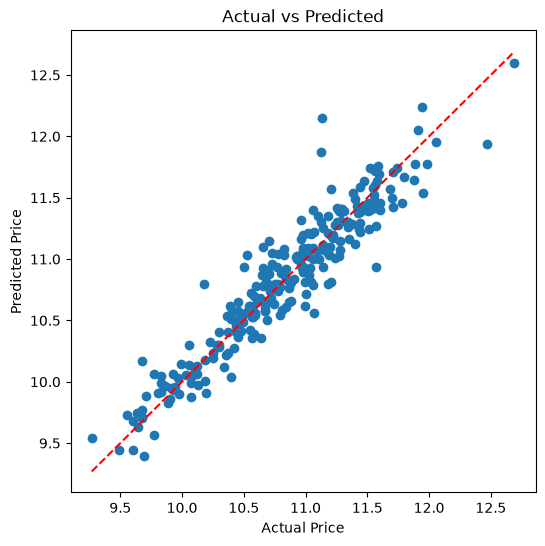

In [78]:
y_pred = xgb_model.predict(X_test)

plt.figure(figsize=(6,6))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")

plt.title("Actual vs Predicted")

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)

plt.show()

## Final Model

In [79]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np

print("="*40)
print("Final XGBoost Model")
print("="*40)

print(f"R² Score : {r2_score(y_test, y_pred):.4f}")
print(f"MAE      : {mean_absolute_error(y_test, y_pred):.4f}")
print(f"RMSE     : {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")

Final XGBoost Model
R² Score : 0.8934
MAE      : 0.1408
RMSE     : 0.1944


## Save the model

In [92]:
import pickle

pickle.dump(
    xgb_model,
    open("../models/laptop_price_predictor.pkl", "wb")
)

# Recommendation System

In [81]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neighbors import NearestNeighbors

In [82]:
recommend_df = df.copy()

X_recommend = recommend_df.drop(columns=['Price'])

In [83]:
categorical_features = [
    'Company',
    'TypeName',
    'Cpu Brand',
    'Gpu Brand',
    'OS'
]

numerical_features = [
    'Ram',
    'Weight',
    'Touchscreen',
    'Ips',
    'PPI',
    'SSD',
    'HDD',
    'Flash',
    'Hybrid'
]

In [84]:
recommend_preprocessor = ColumnTransformer(
    transformers=[
        (
            'cat',
            OneHotEncoder(handle_unknown='ignore'),
            categorical_features
        ),
        (
            'num',
            StandardScaler(),
            numerical_features
        )
    ]
)

In [85]:
X_encoded = recommend_preprocessor.fit_transform(X_recommend)

In [86]:
print(X_encoded.shape)

(1303, 51)


## Train KNN

In [87]:
knn = NearestNeighbors(
    n_neighbors=6,
    metric='cosine'
)

knn.fit(X_encoded)


,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",6
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'cosine'
,"radius radius: float, default=1.0Range of parameter space to use by default for :meth:`radius_neighbors`queries.",1.0
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float (positive), default=2Parameter for the Minkowski metric fromsklearn.metrics.pairwise.pairwise_distances. When p = 1, this isequivalent to using manhattan_distance (l1), and euclidean_distance(l2) for p = 2. For arbitrary p, minkowski_distance (l_p) is used.",2
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
Name,Type,Value
effective_metric_ effective_metric_: strMetric used to compute distances to neighbors.,str,'cosine'
effective_metric_params_ effective_metric_params_: dictParameters for the metric used to compute distances to neighbors.,dict,{}


In [91]:
import pickle

pickle.dump(
    recommend_preprocessor,
    open("../models/recommend_preprocessor.pkl", "wb")
)

pickle.dump(
    knn,
    open("../models/knn_model.pkl", "wb")
)

pickle.dump(
    recommend_df,
    open("../models/recommend_dataset.pkl", "wb")
)

In [89]:
def recommend_laptops(company,typename,inches,resolution,ram,ssd,hdd,weight,touchscreen,ips,cpu_brand,gpu_brand,os):
    x_res, y_res = map(int, resolution.split('x'))

    ppi = np.sqrt(x_res**2 + y_res**2) / inches

    user_data = pd.DataFrame([{
        'Company': company,
        'TypeName': typename,
        'Ram': ram,
        'Weight': weight,
        'Touchscreen': touchscreen,
        'Ips': ips,
        'Cpu Brand': cpu_brand,
        'PPI': ppi,
        'SSD': ssd,
        'HDD': hdd,
        'Flash': 0,
        'Hybrid': 0,
        'Gpu Brand': gpu_brand,
        'OS': os
    }])

    transformed = recommend_preprocessor.transform(user_data)

    distances, indices = knn.kneighbors(
        transformed,
        n_neighbors=5
    )

    recommendations = recommend_df.iloc[indices[0]].copy()
    recommendations['Price'] = np.exp(recommendations['Price']).round(2)
    recommendations['Similarity (%)'] = (
        (1 - distances[0]) * 100
    ).round(2)

    return recommendations[
        [
            'Company',
            'TypeName',
            'Cpu Brand',
            'Ram',
            'SSD',
            'HDD',
            'Gpu Brand',
            'OS',
            'Price',
            'Similarity (%)'
        ]
    ]

In [90]:
recommend_laptops(
    company='Dell',
    typename='Ultrabook',
    inches=15.6,
    resolution='1920x1080',
    ram=16,
    ssd=512,
    hdd=0,
    weight=1.7,
    touchscreen=0,
    ips=1,
    cpu_brand='Intel Core i5',
    gpu_brand='Intel',
    os='Windows'
)

,Company,TypeName,Cpu Brand,Ram,SSD,HDD,Gpu Brand,OS,Price,Similarity (%)
642,Lenovo,Ultrabook,Intel Core i7,16,512,0,Intel,Windows,130536.00,83.78
488,Lenovo,Ultrabook,Intel Core i7,16,512,0,Intel,Windows,95797.44,83.27
80,Dell,Ultrabook,Intel Core i5,8,256,0,Intel,Windows,58403.40,82.84
114,Dell,Ultrabook,Intel Core i5,8,256,0,Intel,Windows,86793.12,79.50
782,Toshiba,Ultrabook,Intel Core i7,16,512,0,Nvidia,Windows,93985.92,78.10
